# Week6_ex1_to_2_analysis - Phase-A Force on a 3-Slot Linear Motor, Fixed and Moving Mover

![Week6_ex1 result](Images/Week6_ex1_result_image.png)

2D Magnetostatic model of a 3-slot linear motor: an air-cored stator with three 100-turn coils (5×15 mm conductors) sits 1 mm above a row of ten NdFe35 magnets (20×5 mm, 26 mm pitch) glued onto a 15 mm steel plate, 40 mm stack depth. Only phase A carries current, $i(t) = 2.25\cos(2\pi \cdot 10\,t + \pi/2) = -2.25\sin\omega t$ A; B and C stay at zero. The stator has no iron, so the force on the coils is plain Lorentz force from the magnet field.

- **Week6_ex1** keeps the mover still, with slot A sitting right over the center of an N magnet (d-axis).
- **Week6_ex2** moves the mover by $v\,t$ with $v = 2\tau/T = 520$ mm/s, so it travels one electrical period (52 mm) during one current period.

This is a light check, done without hypotheses: a 2D charge model of the magnets gives the coil force per amp $\mathbf{K}(x)$ at every mover position, and then $\mathbf{F}(t) = i(t)\,\mathbf{K}(x(t))$ is compared with the FEM sweep. The model was put together after the FEM curves had already been seen, so it is **not a blind prediction**. No FEM number goes into the model, though.

$$F_x = -\!\int J_z B_y\,dA \cdot L,\qquad F_y = \int J_z B_x\,dA \cdot L,\qquad \mathbf{F}(t) = i(t)\,\mathbf{K}\big(x(t)\big)$$

For an ideal sinusoidal field, $K_y \propto \cos\theta$ and $K_x \propto \sin\theta$. With $\theta = \omega t$ and $i \propto -\sin\omega t$, the moving case should give a one-way thrust $\propto \sin^2\omega t$ (mean ≠ 0, pulsating at $2f$) and a normal force $\propto \sin 2\omega t$.

## Week6_ex1 - same motor as Week5_ex3, solved with a different mesh

Week6_ex1 builds exactly the same motor as Week5_ex3: same geometry, magnetization, current expression, `t_sample` sweep and virtual force on the coils. Only the solver settings differ:

| | Week5_ex3 | Week6_ex1 |
|---|---|---|
| Coil/magnet MaxLength | 4 mm | 0.5 mm |
| PercentRefinement / MaximumPasses | 15 / 20 | 30 / 10 |
| Steel | plain `steel_1008` | lamination, stacking factor 0.95 |
| Result export | `get_solution_data()` | report `ExportToFile` |

So this section just fits the same $F = k_1 i + k_2 i^2 + c_0$ model and lines the numbers up against Week5_ex3. The Week5_ex3 values below are the ones reported in `Week5_ex3_analysis.ipynb`. They are typed in rather than read from its CSV, so this notebook doesn't depend on another week's folder.

![Week6_ex1 force vs t_sample](Images/Week6_ex1_force_vs_t_sample.png)

The original plot covers one 10 Hz period (0 to 100 ms). It shows that $F_y$ follows the current and $F_x$ stays near zero. It can't show the sub-percent $i^2$ term or the zero-current offset, so those come from the fit below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4g}".format)

# 1. Week6_ex1 force and current, exported by the original notebook (t_sample in ms, current in A)
f1 = pd.read_csv("Week6_ex1_force.csv")
c1 = pd.read_csv("Week6_ex1_current.csv")
i1 = c1["InputCurrent(winding_a) [A]"].to_numpy()
fx1 = f1["force_virtual.Force_x [newton]"].to_numpy()
fy1 = f1["force_virtual.Force_y [newton]"].to_numpy()

A = np.vstack([i1, i1**2, np.ones_like(i1)]).T
cy = np.linalg.lstsq(A, fy1, rcond=None)[0]
cx = np.linalg.lstsq(A, fx1, rcond=None)[0]
k1 = cy[0]
i_peak = i1.max()

# Week5_ex3 fit, typed in from its analysis output (its CSV stores current in mA)
w5 = {"k1_y": -0.859460, "k2_y": -1.249221e-3, "c0_y": 0.007002, "k1_x": -0.002748, "c0_x": -0.069953, "res_y": 4.151511e-7}

pd.DataFrame({
    "Week5_ex3 (MaxLength 4 mm)": [w5["k1_y"], 100 * w5["k2_y"] * i_peak / w5["k1_y"], w5["k1_x"],
                                   w5["c0_y"], w5["c0_x"], w5["res_y"]],
    "Week6_ex1 (MaxLength 0.5 mm)": [cy[0], 100 * cy[1] * i_peak / cy[0], cx[0],
                                     cy[2], cx[2], np.abs(fy1 - A @ cy).max()],
}, index=["K_y = k1 of F_y [N/A]", "i^2 term of F_y at peak current [%]", "K_x = k1 of F_x [N/A]",
          "F_y offset at i = 0 [N]", "F_x offset at i = 0 [N]", "max F_y fit residual [N]"])

,Week5_ex3 (MaxLength 4 mm),Week6_ex1 (MaxLength 0.5 mm)
K_y = k1 of F_y [N/A],-0.8595,-0.8601
i^2 term of F_y at peak current [%],0.327,0.3291
K_x = k1 of F_x [N/A],-0.002748,-0.002113
F_y offset at i = 0 [N],0.007002,-0.002589
F_x offset at i = 0 [N],-0.06995,0.0008827
max F_y fit residual [N],4.152e-07,8.081e-05


Same motor, same answer: $K_y = -0.860$ N/A in both runs (they differ by 0.08%), and the $i^2$ term is 0.33% at peak current in both. That term is the coil being pulled toward its own image in the steel plate. The thrust constant $K_x$ stays at the 0.3% level of $K_y$, as expected with slot A centered on the d-axis.

What changes is the zero-current offset. In Week5_ex3 it was $-0.070$ N in $F_x$ and $+0.007$ N in $F_y$. With the finer mesh it drops to $+0.0009$ N in $F_x$ (about 80 times smaller) and $-0.0026$ N in $F_y$. With no current there is no Lorentz force on the coils at all, so any nonzero value is a numerical residue of the virtual force calculation, and shrinking it with mesh refinement fits that reading. MaximumPasses and the steel stacking changed too, though, so this shows the offset depends on the solver settings without pinning it on one of them.

The finer run fits a little less cleanly, though: the largest $F_y$ residual is about 8e-5 N against 4e-7 N in Week5_ex3. A 0.5 mm MaxLength runs into the 2D Student mesh cap, so each sweep point probably ends on a slightly different capped mesh, while the coarse 4 mm mesh likely came out the same every time. This is still under 0.01% of the peak force.

## 2D charge model of the magnet row

Each magnet is replaced by surface charges $\pm M$ on its top and bottom faces. The steel plate is treated as an infinitely permeable plane at $y = 7.5$ mm. Its image charges then cancel the bottom-face charges and put an opposite-sign copy of each top-face charge at $y = 2.5$ mm. The magnet row is finite (ten magnets, ±127 mm), which matters near the ends.

$M$ isn't held rigid. NdFe35 has recoil permeability $\mu_r = 1.0998$, so the magnet's own demagnetizing field (plus its image) lowers it:

$$M = \frac{\mu_r H_c}{1 + (\mu_r - 1)\,N_\text{eff}},\qquad N_\text{eff} = -\langle H_y\rangle_\text{magnet}\big/M$$

where $N_\text{eff}$ is the average internal field of a magnet near the middle of the row, computed from all charges and images. The force is the Lorentz force on phase A's two coil sides (±100 turns × $i$ over 5×15 mm), times the 40 mm depth. Coil positions come from the original notebook's move chain: slot A ends up centered at $x = -39$ mm, exactly over an N magnet.

In [2]:
# 2. Geometry rebuilt from the original notebook's create/duplicate/move chain (mm)
mu0 = 4e-7 * np.pi
mm = 1e-3
depth = 40 * mm
mag_top, iron_top = 12.5, 7.5                       # magnet top face, steel plate top face
s_centers = [-117 + 52 * k for k in range(5)]        # magnet_s, magnetized -y
n_centers = [-91 + 52 * k for k in range(5)]         # magnet_n, magnetized +y
coil_a_sides = [(-47.0, -42.0), (-36.0, -31.0)]      # phase A conductors, x range
coil_y = (13.5, 28.5)                                # coil y range
mu_r, Hc = 1.0997785406, 890000.0                    # NdFe35, from the AEDT material library
turns, A_cond = 100, 5 * 15 * mm * mm

# 3. Field of the charged sheets (2D: each sheet is infinite in z)
def sheets(shift, M):
    out = []
    for xc, s in [(c, -1) for c in s_centers] + [(c, +1) for c in n_centers]:
        x1, x2 = xc - 10 + shift, xc + 10 + shift
        out.append((x1, x2, mag_top, s * M))                    # top face
        out.append((x1, x2, 2 * iron_top - mag_top, -s * M))    # image of the top face in the steel
    return out

def field(x, y, S):
    Hx = np.zeros_like(x)
    Hy = np.zeros_like(x)
    for x1, x2, y0, sig in S:
        d = y - y0
        Hx += sig / (4 * np.pi) * np.log(((x - x1)**2 + d**2) / ((x - x2)**2 + d**2))
        Hy += sig / (2 * np.pi) * (np.arctan((x - x1) / d) - np.arctan((x - x2) / d))
    return Hx, Hy

gx, gw = np.polynomial.legendre.leggauss(20)

def grid(x1, x2, y1, y2):
    X = (x2 - x1) / 2 * gx + (x2 + x1) / 2
    Y = (y2 - y1) / 2 * gx + (y2 + y1) / 2
    XX, YY = np.meshgrid(X, Y, indexing="ij")
    W = np.outer(gw, gw) * (x2 - x1) * (y2 - y1) / 4
    return XX, YY, W

# 4. Self-consistent M from the average internal field of the magnet_n at x = 13 mm
XX, YY, W = grid(3.0, 23.0, iron_top + 1e-6, mag_top - 1e-6)
N_eff = -np.sum(W * field(XX, YY, sheets(0.0, 1.0))[1]) / np.sum(W)
M_rigid = mu_r * Hc
M_sc = M_rigid / (1 + (mu_r - 1) * N_eff)

# 5. Lorentz force on phase A per amp of winding current, for a given mover shift
def K(shift, M):
    S = sheets(shift, M)
    F = np.zeros(2)
    for sign, (x1, x2) in zip([+1, -1], coil_a_sides):
        XX, YY, W = grid(x1, x2, *coil_y)
        Hx, Hy = field(XX, YY, S)
        Jz = sign * turns / A_cond
        dA = W * mm * mm
        F += depth * np.array([np.sum(dA * (-Jz * mu0 * Hy)), np.sum(dA * (Jz * mu0 * Hx))])
    return F

K_rigid, K_sc = K(0.0, M_rigid), K(0.0, M_sc)
pd.DataFrame({
    "K_x [N/A]": [K_rigid[0], K_sc[0], np.linalg.lstsq(A, fx1, rcond=None)[0][0]],
    "K_y [N/A]": [K_rigid[1], K_sc[1], k1],
    "K_y vs FEM [%]": [100 * (K_rigid[1] / k1 - 1), 100 * (K_sc[1] / k1 - 1), 0.0],
}, index=[f"charge model, rigid M", f"charge model, self-consistent M (N_eff = {N_eff:.3f}, M {100*(M_sc/M_rigid-1):+.1f}%)", "Week6_ex1 FEM fit"])

,K_x [N/A],K_y [N/A],K_y vs FEM [%]
"charge model, rigid M",-0.002183,-0.9187,6.809
"charge model, self-consistent M (N_eff = 0.546, M -5.2%)",-0.00207,-0.8712,1.29
Week6_ex1 FEM fit,-0.002113,-0.8601,0


At the d-axis, rigid $M$ gives $K_y = 0.919$ N/A, which is the same 2D estimate Week5_ex3 got. With the recoil correction ($M$ drops about 5%), it comes down to 0.871 N/A, within 1.3% of the FEM fit. The coil-side sign convention picked in `# 5.` happens to match the winding polarity in AEDT, so the signs line up too. Even the tiny $K_x$, an end-of-row asymmetry of about 0.2% of $K_y$, agrees within 2% with the finer-mesh run. The coarser Week5_ex3 run had $-0.00275$ N/A there. From here on the self-consistent model is used as-is.

## Week6_ex2 - mover moving one electrical period

![Week6_ex2 result](../Week6_ex2/Images/Week6_ex2_result_image.png)

Week6_ex2 differs from ex1 in exactly one place: the steel plate and all ten magnets are moved by `veolcity_stator*t_sample` (520 mm/s, so 2.6 mm per 5 ms step) before the region is drawn. Everything else, including the mesh settings, is identical. At $t = 0$ both runs solve the same geometry with zero current, and both leave the same small residue ($F_y \approx -0.0026$ N, $F_x \approx 0.001$ N).

![Week6_ex2 force vs t_sample](../Week6_ex2/Images/Week6_ex2_force_vs_t_sample.png)

The plot shows a one-sided $F_x$ and an $F_y$ at twice the current frequency. It doesn't show how far those shapes are from pure sinusoids, which is what the comparison below is about.

In [3]:
# 6. Week6_ex2 force and current, exported by the original notebook, against the model at each mover position
f2 = pd.read_csv("../Week6_ex2/Week6_ex2_force.csv")
c2 = pd.read_csv("../Week6_ex2/Week6_ex2_current.csv")
t2 = f2["t_sample [ms]"].to_numpy(dtype=float)
i2 = c2["InputCurrent(winding_a) [A]"].to_numpy()
shift = 0.52 * t2                                   # mm, v = 520 mm/s
K2 = np.array([K(s, M_sc) for s in shift])
F_model = K2 * i2[:, None]

df2 = pd.DataFrame({
    "t [ms]": t2,
    "shift [mm]": shift,
    "i_a [A]": i2,
    "K_x [N/A]": K2[:, 0],
    "K_y [N/A]": K2[:, 1],
    "F_x FEM [N]": f2["force_virtual.Force_x [newton]"],
    "F_x model [N]": F_model[:, 0],
    "F_y FEM [N]": f2["force_virtual.Force_y [newton]"],
    "F_y model [N]": F_model[:, 1],
})
df2.round(4)

,t [ms],shift [mm],i_a [A],K_x [N/A],K_y [N/A],F_x FEM [N],F_x model [N],F_y FEM [N],F_y model [N]
0,0,0,0,-0.0021,-0.8712,0.0009,-0,-0.0026,-0
1,5,2.6,-0.6953,0.2184,-0.8737,-0.1469,-0.1518,0.5981,0.6074
2,10,5.2,-1.323,0.489,-0.8133,-0.6364,-0.6467,1.064,1.076
3,15,7.8,-1.82,0.7481,-0.6464,-1.351,-1.362,1.174,1.177
4,20,10.4,-2.14,0.9648,-0.3829,-2.06,-2.065,0.8169,0.8195
5,25,13,-2.25,1.068,-0.0013,-2.401,-2.404,-0.0036,0.0029
6,30,15.6,-2.14,0.9644,0.3803,-2.059,-2.064,-0.8243,-0.8139
7,35,18.2,-1.82,0.7472,0.6437,-1.349,-1.36,-1.185,-1.172
8,40,20.8,-1.323,0.4877,0.8105,-0.6329,-0.6451,-1.073,-1.072
9,45,23.4,-0.6953,0.2166,0.8707,-0.1462,-0.1506,-0.6025,-0.6054


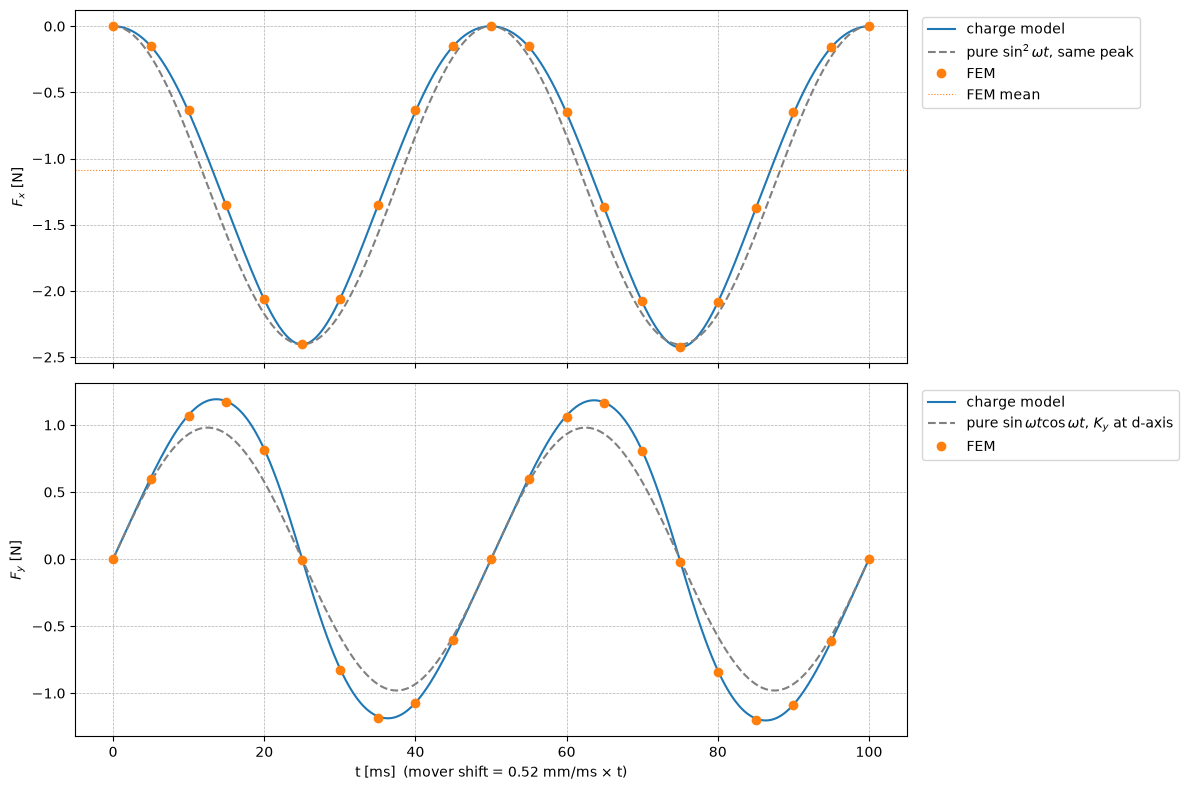

In [4]:
# 7. FEM vs charge model, with the pure-sinusoid shapes for reference
tt = np.linspace(0, 100, 401)
sh = 0.52 * tt
ii = -2.25 * np.sin(2 * np.pi * 10 * tt / 1000)
Kf = np.array([K(s, M_sc) for s in sh])
wt = 2 * np.pi * 10 * tt / 1000
Kx_q = K2[5, 0]                                     # model K_x at the q-axis (t = 25 ms)
Ky_d = K2[0, 1]                                     # model K_y at the d-axis (t = 0)

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(tt, ii * Kf[:, 0], label="charge model")
ax[0].plot(tt, -2.25 * Kx_q * np.sin(wt)**2, "--", color="gray", label="pure $\\sin^2\\omega t$, same peak")
ax[0].plot(t2, df2["F_x FEM [N]"], "o", label="FEM")
ax[0].axhline(df2["F_x FEM [N]"][:-1].mean(), color="C1", lw=0.8, ls=":", label="FEM mean")
ax[0].set_ylabel("$F_x$ [N]")
ax[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax[0].grid(True, ls="--", lw=0.5)

ax[1].plot(tt, ii * Kf[:, 1], label="charge model")
ax[1].plot(tt, -2.25 * Ky_d * np.sin(wt) * np.cos(wt), "--", color="gray", label="pure $\\sin\\omega t\\cos\\omega t$, $K_y$ at d-axis")
ax[1].plot(t2, df2["F_y FEM [N]"], "o", label="FEM")
ax[1].set_xlabel("t [ms]  (mover shift = 0.52 mm/ms × t)")
ax[1].set_ylabel("$F_y$ [N]")
ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax[1].grid(True, ls="--", lw=0.5)

plt.tight_layout()
plt.savefig("Images/Week6_ex2_force_vs_charge_model.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# 8. Headline numbers, FEM vs model
fx_f, fx_m = df2["F_x FEM [N]"].to_numpy(), df2["F_x model [N]"].to_numpy()
fy_f, fy_m = df2["F_y FEM [N]"].to_numpy(), df2["F_y model [N]"].to_numpy()
rows = {
    "F_x peak, first half (t = 25 ms) [N]": (fx_f[5], fx_m[5]),
    "F_x peak, second half (t = 75 ms) [N]": (fx_f[15], fx_m[15]),
    "F_x mean over one period [N]": (fx_f[:-1].mean(), fx_m[:-1].mean()),
    "F_y at t = 15 ms [N]": (fy_f[3], fy_m[3]),
    "F_y at t = 10 ms [N]": (fy_f[2], fy_m[2]),
    "F_y at t = 35 ms [N]": (fy_f[7], fy_m[7]),
}
summary = pd.DataFrame(rows, index=["FEM", "model"]).T
summary["model vs FEM [%]"] = 100 * (summary["model"] / summary["FEM"] - 1)
summary.round(4)

,FEM,model,model vs FEM [%]
"F_x peak, first half (t = 25 ms) [N]",-2.401,-2.404,0.1165
"F_x peak, second half (t = 75 ms) [N]",-2.424,-2.426,0.0798
F_x mean over one period [N],-1.085,-1.092,0.5937
F_y at t = 15 ms [N],1.174,1.177,0.2163
F_y at t = 10 ms [N],1.064,1.076,1.047
F_y at t = 35 ms [N],-1.185,-1.172,-1.079


## Conclusion

**Week6_ex1.** This is Week5_ex3 solved again with a finer mesh, and it gives the same physics: $K_y = -0.860$ N/A, an $i^2$ term of 0.33% at peak current, and almost no $F_x$ because slot A sits on the d-axis. The 2D charge model with recoil-corrected $M$ lands within 1.3% of $K_y$. The zero-current offset in $F_x$ dropped from $-0.070$ N to $+0.0009$ N with the finer mesh, which supports reading it as a virtual-force numerical offset rather than a physical force.

**Week6_ex2.** Moving the mover in step with the current turns the same coil into a single-phase linear motor. The thrust never changes sign: it pulses between 0 and about $-2.4$ N at twice the current frequency, with a mean of $-1.09$ N on the coils, so the mover is pushed $+x$, the direction it's moving. The normal force swings both ways at $2f$. The charge model follows the FEM within about 1% for $F_x$ over the whole sweep and gets the mean thrust within 0.6%.

Neither force is the pure sinusoid from the title cell, and the model shows why. $K_y$ stays nearly flat near the d-axis, since a 20 mm magnet looks almost uniform from a coil side for the first few mm of travel. So $F_y$ peaks later, around 14 ms instead of 12.5 ms, and higher (1.17 N at the 15 ms sample) than the 0.98 N a $\cos$-shaped $K_y$ would give. The constants also differ: $K_x$ at the q-axis (1.07 N/A) is larger than $K_y$ at the d-axis (0.87 N/A), since the two components come from different parts of the magnet field. The second-half thrust peak is about 1% larger than the first ($-2.424$ vs $-2.401$ N). The model gets the same split ($-2.426$ vs $-2.404$), because by then the coil has moved 52 mm closer to the end of the finite magnet row.

What the model leaves out (the coil's image attraction, about 0.3%, and the virtual-force offset, about 0.003 N) is smaller than the remaining 1% gap, so there's nothing left here worth chasing.